# Industry Structure — Data Withheld on Purpose, and Published as Zero

**Artifact class:** `tutorial`  ·  **Data mode:** `empirical`  ·  **Vintage:** BLS QCEW 2024 Q1 (reference period; NOT a pinned vintage)

This corpus has now met three regimes of imperfect data: ACS publishes a **margin of error**, LAUS
publishes **nothing** because its estimates are model output, and FRED **revises** what it already
published. QCEW is a fourth, and the most hazardous of the four, because its imperfection is
deliberate, targeted, and invisible in the numbers.

QCEW is a near-census of employment drawn from unemployment-insurance records — far more complete
than any survey. But the Bureau **withholds** any cell where disclosing it could identify an
employer. Three properties follow, and each one breaks a routine analysis:

1. **A withheld cell is published as `0`, not as blank.** A plain `sum()` counts withheld
   industries as industries with no employment.
2. **Suppression is not missing-at-random.** It is applied where few establishments would make a
   cell identifying, so it is *caused by* industry concentration — the thing an industry-structure
   analysis is usually about.
3. **It is worst exactly where the data is most needed.** The finer the industry detail and the
   smaller the place, the more is withheld.

All three are measured below rather than described.

Real data only. No synthetic fallback. *Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

1. **Distinguish** disclosure suppression from sampling error and from model uncertainty, and say
   which analytical tools each one disables.
2. **Detect** a sentinel that is a plausible value — a withheld cell published as `0` — and
   quantify the error that treating it as data produces.
3. **Measure** the precision-versus-coverage trade-off imposed by disclosure policy across levels
   of industry detail.
4. **Establish** that missingness is informative by relating it to a variable the publisher *does*
   disclose, and extract what a suppression flag itself tells you.
5. **Compare** suppression across areas and recognise the inverse relationship between how much
   detail is published and how much a small economy needs it.
6. **Report** a share-of-total statistic honestly when the denominator's components are partly
   withheld.

## Prerequisites

**Knowledge.** D01 (ACS jam values — the same defect shape in another publisher's data) and D02
(LAUS, the other BLS programme and a different uncertainty regime).

**Setup.** **No API key is required.** QCEW is the one source in this corpus with no credential to
leak and no quota to exhaust.

**Packages.** `pandas`, `numpy`, `matplotlib`, and `krl_tutorials_data`.

## Data Provenance

**BLS Quarterly Census of Employment and Wages**, 2024 Q1, by area, via the open CSV endpoint
`data.bls.gov/cew/data/api/{year}/{qtr}/area/{area}.csv`.

| Field | Role |
|---|---|
| `disclosure_code` | `N` marks a withheld cell. The whole notebook turns on this column. |
| `agglvl_code` | Level of industry detail: 73 ≈ NAICS sector, 78 ≈ 6-digit industry |
| `own_code` | Ownership; `5` is private |
| `qtrly_estabs` | Establishment count — **disclosed even when the cell is suppressed** |
| `month3_emplvl` | Employment — withheld, and published as `0`, when suppressed |

**QCEW is a census, not a survey.** It covers employers subject to unemployment-insurance law,
which is roughly 95% of civilian jobs. There is no sampling margin of error to compute, and the
uncertainty that matters is not statistical: it is what the Bureau has chosen not to tell you, and
why.

`fetch_qcew` converts withheld values to `NaN` and records how many it converted. The count appears
in the provenance record, so how much of a slice was withheld is visible rather than inferred from
a suspiciously round total.

In [1]:
"""Configuration. Areas span four orders of magnitude of employment, on purpose."""
from __future__ import annotations

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src")); break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data.sources import (
    verify_digest,
    fetch_qcew, DataAccessError, QCEW_SUPPRESSED, QCEW_SUPPRESSED_FIELDS,
)

YEAR, QUARTER = 2024, 1
PRIVATE = "5"

# QCEW aggregation levels within a county, coarse to fine. The label is what the
# level means; the code is positional and unreadable on its own (defect F-13).
AGG_LEVELS = {
    "73": "NAICS sector (2-digit)",
    "74": "NAICS supersector",
    "75": "NAICS 3-digit",
    "76": "NAICS 4-digit",
    "77": "NAICS 5-digit",
    "78": "NAICS 6-digit industry",
}
DETAIL_LEVEL = "78"     # the finest, where suppression bites hardest
SECTOR_LEVEL = "73"     # the coarsest, used as the control total

# Areas chosen to span size, not to be representative of anywhere.
AREAS = {
    "51059": "Fairfax County, VA",
    "51013": "Arlington County, VA",
    "51600": "Fairfax city, VA",
    "51750": "Radford city, VA",
    "51720": "Norton city, VA",
}
FOCUS_AREA = "51059"
CONTACT = None          # set to an email to identify this client to BLS

ESTAB_BUCKETS = [0, 3, 10, 50, np.inf]
ESTAB_LABELS = ["1-3", "4-10", "11-50", "50+"]

pd.set_option("display.width", 150)
plt.rcParams["figure.dpi"] = 110

print(f"Vintage        : QCEW {YEAR} Q{QUARTER} (reference period; NOT a pinned vintage)")
print(f"Ownership      : own_code {PRIVATE} (private)")
print(f"Detail levels  : {len(AGG_LEVELS)}")
for _c, _l in AGG_LEVELS.items():
    print(f"  agglvl {_c}  {_l}")
print(f"Areas          : {len(AREAS)}")
print(f"Suppression    : disclosure_code == {QCEW_SUPPRESSED!r}")
print(f"Fields blanked : {len(QCEW_SUPPRESSED_FIELDS)} (establishment count excepted)")
print("Credential     : none required")

#: One digest per area, recorded when this notebook was written. QCEW is
#: revised and serves no prior vintage, so the quarter names a reference
#: period; these pins do not restore a vintage, they guarantee a revision
#: raises here instead of quietly changing the figures below.
PINNED_QCEW = {
    "51013": "121705c49ef2eac69f264132835badc3b100b9a0052871f115e25c39c7354115",
    "51059": "ab8bda730609854300198e259676626d19f76356f1c32a77a10ef37afe71b3b1",
    "51600": "5fc6aa6ed43819afea67124cd07b70d4f3e83781520ee9229d97d4cfefeb417d",
    "51720": "87a20f0472b6b3fa6418dce9cf56f865bacb70c42c382411154c37880cd3e095",
    "51750": "ff3a948e4c5b71b2f25d8160a92f43de6e56cad5b8bd6c46ec13a6a59adf4bb6",
}


Vintage        : QCEW 2024 Q1 (reference period; NOT a pinned vintage)
Ownership      : own_code 5 (private)
Detail levels  : 6
  agglvl 73  NAICS sector (2-digit)
  agglvl 74  NAICS supersector
  agglvl 75  NAICS 3-digit
  agglvl 76  NAICS 4-digit
  agglvl 77  NAICS 5-digit
  agglvl 78  NAICS 6-digit industry
Areas          : 5
Suppression    : disclosure_code == 'N'
Fields blanked : 8 (establishment count excepted)
Credential     : none required


In [2]:
try:
    slices, provenance = {}, {}
    for _area in AREAS:
        _df, _prov = verify_digest(
            fetch_qcew(year=YEAR, quarter=QUARTER, area=_area, contact=CONTACT),
            PINNED_QCEW[_area], label=f"QCEW {_area}",
        )
        slices[_area] = _df
        provenance[_area] = _prov
except DataAccessError as exc:
    print("HALTED - real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    print("\nNo synthetic fallback exists by design.")
    raise

focus = slices[FOCUS_AREA]
private = focus.loc[focus.own_code == PRIVATE].copy()

print(f"{AREAS[FOCUS_AREA]}, {YEAR} Q{QUARTER}")
print(f"  rows returned        : {len(focus):,}")
print(f"  private-sector rows  : {len(private):,}")
print()
print(provenance[FOCUS_AREA].render())

Fairfax County, VA, 2024 Q1
  rows returned        : 2,015
  private-sector rows  : 1,610

Source      : U.S. Bureau of Labor Statistics - QCEW area 51059, 2024 Q1
Vintage     : 2024Q1  (pinned)
Endpoint    : https://data.bls.gov/cew/data/api/2024/1/area/51059.csv
Retrieved   : 2026-09-18T12:40:53+00:00
Shape       : 2015 rows x 43 cols
Payload hash: ab8bda7306098543...  (response-bytes)
Data mode   : EMPIRICAL
Variables   :
              qtrly_estabs     QCEW field
              month1_emplvl    QCEW field
              month2_emplvl    QCEW field
              month3_emplvl    QCEW field
              total_qtrly_wages QCEW field
              taxable_qtrly_wages QCEW field
              qtrly_contributions QCEW field
              avg_wkly_wage    QCEW field
Limitations :
              - 586 of 2015 rows carry disclosure_code 'N' (withheld to protect employer identity).
              - 4102 withheld values were published as 0 and have been set to NaN. Summing them as zeros would tre

## 1. The price of detail

Disclosure suppression creates a trade-off with the same shape as the sampling one in D16 — finer
resolution costs you coverage — but produced by policy rather than by sample size. Because it is a
rule rather than a variance, it is exactly measurable.

In [3]:
rows = []
for code_, label in AGG_LEVELS.items():
    sub = private.loc[private.agglvl_code == code_]
    if sub.empty:
        continue
    rows.append({
        "agglvl": code_,
        "detail": label,
        "cells": len(sub),
        "suppressed": int(sub.suppressed.sum()),
        "suppressed_pct": float(sub.suppressed.mean() * 100),
    })
ladder = pd.DataFrame(rows)
print(f"{AREAS[FOCUS_AREA]} - suppression by level of industry detail")
print(ladder.to_string(index=False, formatters={"suppressed_pct": "{:.1f}".format}))
print()
_coarse = ladder.iloc[0]
_fine = ladder.loc[ladder.agglvl == DETAIL_LEVEL].iloc[0]
print(f"At {_coarse.detail} nothing is withheld ({_coarse.suppressed}/{_coarse.cells}).")
print(f"At {_fine.detail} {_fine.suppressed_pct:.1f}% of cells are "
      f"({_fine.suppressed}/{_fine.cells}).")
print("Detail is not free, and what it costs is not precision but coverage.")

Fairfax County, VA - suppression by level of industry detail
agglvl                 detail  cells  suppressed suppressed_pct
    73 NAICS sector (2-digit)     11           0            0.0
    74      NAICS supersector     20           0            0.0
    75          NAICS 3-digit     84          12           14.3
    76          NAICS 4-digit    261          73           28.0
    77          NAICS 5-digit    530         207           39.1
    78 NAICS 6-digit industry    701         294           41.9

At NAICS sector (2-digit) nothing is withheld (0/11).
At NAICS 6-digit industry 41.9% of cells are (294/701).
Detail is not free, and what it costs is not precision but coverage.


## 2. A withheld cell is published as zero

This is the trap. QCEW does not leave a suppressed employment figure blank — it writes `0`, which
is a perfectly plausible value for a small industry.

**It is worth being precise about where the damage lands, because the obvious guess is wrong.** A
`sum()` is *not* affected: adding 294 zeros changes a total by zero. The sum is short against the
control total, but it is short because the employment is genuinely absent from the disclosed cells,
not because zeros were introduced.

What the false zeros corrupt is everything computed **per cell** — the mean, the median, the
minimum, the distribution, and any count of industries with no employment. Those are the statistics
an industry-structure analysis actually uses, and each is shown below against the corrected version.

`fetch_qcew` has already converted the zeros to `NaN`; the naive figures are reconstructed with
`fillna(0)`.

In [4]:
detail = private.loc[private.agglvl_code == DETAIL_LEVEL].copy()
sector = private.loc[private.agglvl_code == SECTOR_LEVEL]

control_total = float(sector.month3_emplvl.sum())
disclosed_total = float(detail.month3_emplvl.sum())          # NaN-skipping
withheld = control_total - disclosed_total
naive = detail.month3_emplvl.fillna(0)                        # the published zeros restored

print(f"{AREAS[FOCUS_AREA]}, private employment, month 3 of {YEAR}Q{QUARTER}")
print(f"  control total from {AGG_LEVELS[SECTOR_LEVEL]:<24} {control_total:>12,.0f}")
print(f"  sum of DISCLOSED {AGG_LEVELS[DETAIL_LEVEL]:<26} {disclosed_total:>12,.0f}")
print(f"  withheld, therefore                              {withheld:>12,.0f}   "
      f"({withheld / control_total:.1%} of employment)")
print()
print("  Where the false zeros do and do not matter:")
print(f"{'statistic':<34}{'naive (zeros)':>16}{'corrected':>13}{'error':>12}")
_rows = [
    ("sum", float(naive.sum()), disclosed_total),
    ("mean employment per cell", float(naive.mean()),
     float(detail.month3_emplvl.mean())),
    ("median employment per cell", float(naive.median()),
     float(detail.month3_emplvl.median())),
    ("cells reported as zero-employment", float((naive == 0).sum()),
     float((detail.month3_emplvl == 0).sum())),
    ("smallest non-missing value", float(naive.min()),
     float(detail.month3_emplvl.min())),
]
for label, bad, good in _rows:
    _err = "none" if np.isclose(bad, good) else f"{(bad - good) / good:+.1%}" if good else "n/a"
    print(f"  {label:<32}{bad:>16,.0f}{good:>13,.0f}{_err:>12}")
print()
print("  The sum is identical: adding zeros changes a total by zero. Every PER-CELL")
print("  statistic is wrong, and the mean - the one most likely to be quoted as")
print("  'average employment per industry' - is the worst affected.")
print()
print(f"Two numbers describe the same suppression and they are very different:")
print(f"  {_fine.suppressed_pct:.1f}% of CELLS are withheld")
print(f"  {withheld / control_total:.1%} of EMPLOYMENT is withheld")
print("Counting cells overstates the loss, because suppression falls on small cells.")
print("Counting employment understates how much of the industry STRUCTURE is hidden,")
print("because the hidden part is many small industries rather than a few large ones.")
print()
_shares = detail.month3_emplvl / control_total
print(f"Industry shares computed from the disclosed cells sum to "
      f"{_shares.sum():.1%}, not 100%.")
print("A share table built from this without saying so has a missing category it")
print("does not name.")

Fairfax County, VA, private employment, month 3 of 2024Q1
  control total from NAICS sector (2-digit)        540,812
  sum of DISCLOSED NAICS 6-digit industry          488,765
  withheld, therefore                                    52,047   (9.6% of employment)

  Where the false zeros do and do not matter:
statistic                            naive (zeros)    corrected       error
  sum                                      488,765      488,765        none
  mean employment per cell                     697        1,201      -41.9%
  median employment per cell                    28          233      -88.0%
  cells reported as zero-employment             308           14    +2100.0%
  smallest non-missing value                     0            0        none

  The sum is identical: adding zeros changes a total by zero. Every PER-CELL
  statistic is wrong, and the mean - the one most likely to be quoted as
  'average employment per industry' - is the worst affected.

Two numbers describe

## 3. The missingness is informative

Suppression is applied because a cell has too few establishments to be disclosed safely. The
establishment count is itself published, even for suppressed cells — so the rule the Bureau applied
can be recovered from the data, and the suppression flag can be read as a signal rather than a gap.

That inverts the usual handling. A suppressed cell is not an absence of information; it is a
statement that the industry in this place is concentrated in very few employers.

In [5]:
detail = detail.assign(
    estab_bucket=pd.cut(detail.qtrly_estabs, ESTAB_BUCKETS, labels=ESTAB_LABELS)
)
print(f"Establishment count is disclosed for "
      f"{int(detail.loc[detail.suppressed, 'qtrly_estabs'].notna().sum())} of "
      f"{int(detail.suppressed.sum())} suppressed cells")
print()
print(f"  median establishments, suppressed cells : "
      f"{detail.loc[detail.suppressed, 'qtrly_estabs'].median():>5.0f}")
print(f"  median establishments, disclosed cells  : "
      f"{detail.loc[~detail.suppressed, 'qtrly_estabs'].median():>5.0f}")
print()
print("  suppression rate by establishment count:")
for bucket, grp in detail.groupby("estab_bucket", observed=True):
    print(f"    {bucket:<7} n={len(grp):>4}   suppressed {grp.suppressed.mean():>6.1%}")
print()
from scipy import stats as _stats

_pearson = float(np.corrcoef(
    detail.qtrly_estabs.fillna(0), detail.suppressed.astype(float))[0, 1])
_corr = float(_stats.spearmanr(
    detail.qtrly_estabs.fillna(0), detail.suppressed.astype(float)).statistic)
print(f"  rank correlation (Spearman), establishments with suppression: {_corr:+.3f}")
print(f"  linear correlation (Pearson) for comparison                 : {_pearson:+.3f}")
print()
print("  The Pearson figure understates the relationship badly. Establishment count is")
print("  heavily right-skewed and the disclosure rule is a step, not a line, so a linear")
print("  coefficient is the wrong summary - the bucket gradient above is the honest one.")
print()
print("The gradient is the disclosure rule made visible. A cell with one to three")
print("establishments is withheld almost always; one with fifty or more almost never.")
print("So the flag carries information: it identifies the concentrated industries,")
print("which is often the question an industry-structure analysis is asking.")

Establishment count is disclosed for 294 of 294 suppressed cells

  median establishments, suppressed cells :     2
  median establishments, disclosed cells  :    25

  suppression rate by establishment count:
    1-3     n= 214   suppressed  95.3%
    4-10    n= 126   suppressed  40.5%
    11-50   n= 216   suppressed  16.7%
    50+     n= 131   suppressed   2.3%

  rank correlation (Spearman), establishments with suppression: -0.667
  linear correlation (Pearson) for comparison                 : -0.221

  The Pearson figure understates the relationship badly. Establishment count is
  heavily right-skewed and the disclosure rule is a step, not a line, so a linear
  coefficient is the wrong summary - the bucket gradient above is the honest one.

The gradient is the disclosure rule made visible. A cell with one to three
establishments is withheld almost always; one with fifty or more almost never.
So the flag carries information: it identifies the concentrated industries,
which is often 

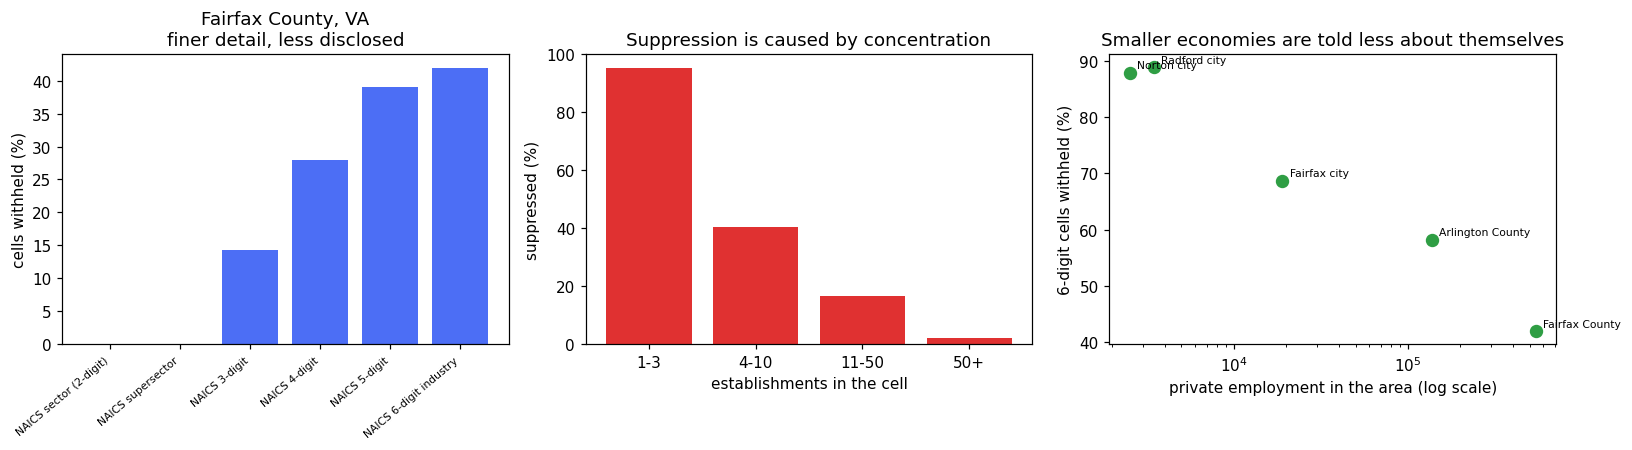

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].bar(ladder.detail, ladder.suppressed_pct, color="#4c6ef5")
axes[0].set_ylabel("cells withheld (%)")
axes[0].set_title(f"{AREAS[FOCUS_AREA]}\nfiner detail, less disclosed")
axes[0].tick_params(axis="x", rotation=40, labelsize=7)
for _t in axes[0].get_xticklabels():
    _t.set_ha("right")

_rates = detail.groupby("estab_bucket", observed=True).suppressed.mean() * 100
axes[1].bar(_rates.index.astype(str), _rates.values, color="#e03131")
axes[1].set_xlabel("establishments in the cell")
axes[1].set_ylabel("suppressed (%)")
axes[1].set_title("Suppression is caused by concentration")

area_rows = []
for area, df in slices.items():
    d = df.loc[(df.own_code == PRIVATE) & (df.agglvl_code == DETAIL_LEVEL)]
    s = df.loc[(df.own_code == PRIVATE) & (df.agglvl_code == SECTOR_LEVEL)]
    if d.empty or s.empty:
        continue
    area_rows.append({
        "area": AREAS[area],
        "employment": float(s.month3_emplvl.sum()),
        "cells": len(d),
        "suppressed_pct": float(d.suppressed.mean() * 100),
    })
areas_df = pd.DataFrame(area_rows).sort_values("employment")
axes[2].scatter(areas_df.employment, areas_df.suppressed_pct, s=60, color="#2f9e44")
for _, r in areas_df.iterrows():
    axes[2].annotate(r.area.split(",")[0], (r.employment, r.suppressed_pct),
                     fontsize=7, xytext=(5, 3), textcoords="offset points")
axes[2].set_xscale("log")
axes[2].set_xlabel("private employment in the area (log scale)")
axes[2].set_ylabel("6-digit cells withheld (%)")
axes[2].set_title("Smaller economies are told less about themselves")
plt.tight_layout(); plt.show()

## 4. Least available where most needed

A large county can describe its own industry structure in detail. A small one cannot — not because
its data is noisier, but because in a small economy almost every detailed industry has few enough
employers to be identifying.

The places whose economies are most exposed to a single employer are the places least able to
publish that fact.

In [7]:
print(f"6-digit private-sector suppression by area size, {YEAR}Q{QUARTER}")
print(f"{'area':<26}{'employment':>13}{'cells':>8}{'withheld %':>12}")
for _, r in areas_df.iterrows():
    print(f"{r.area:<26}{r.employment:>13,.0f}{r.cells:>8,}{r.suppressed_pct:>11.1f}%")
print()
_small, _large = areas_df.iloc[0], areas_df.iloc[-1]
print(f"{_small.area} withholds {_small.suppressed_pct:.1f}% of its detailed cells; "
      f"{_large.area}")
print(f"withholds {_large.suppressed_pct:.1f}%. The gap is "
      f"{_small.suppressed_pct - _large.suppressed_pct:.1f} percentage points, and it runs the")
print("wrong way for anyone studying small local economies.")
print()
if len(areas_df) > 2:
    _c = np.corrcoef(np.log(areas_df.employment), areas_df.suppressed_pct)[0, 1]
    print(f"correlation, log employment with suppression rate: {_c:+.3f} "
          f"across {len(areas_df)} areas")
    print("Reported as a description of these areas, not as an estimate for all areas:")
    print("five places chosen to span size are not a sample of anything.")

6-digit private-sector suppression by area size, 2024Q1
area                         employment   cells  withheld %
Norton city, VA                   2,522     107       87.9%
Radford city, VA                  3,461     153       88.9%
Fairfax city, VA                 18,961     307       68.7%
Arlington County, VA            136,610     512       58.2%
Fairfax County, VA              540,812     701       41.9%

Norton city, VA withholds 87.9% of its detailed cells; Fairfax County, VA
withholds 41.9%. The gap is 45.9 percentage points, and it runs the
wrong way for anyone studying small local economies.

correlation, log employment with suppression rate: -0.991 across 5 areas
Reported as a description of these areas, not as an estimate for all areas:
five places chosen to span size are not a sample of anything.


## Limitations

- **Suppression is a rule, not a random process**, so nothing here is a sampling statement and no
  interval is computable. The withheld employment is bounded below by zero and above by the control
  total's residual, and nothing narrower is available from published data.
- **Five areas, chosen to span size.** They are an illustration of a gradient, not a sample. The
  correlation reported in section 4 describes these five places only.
- **One quarter, one state's areas.** Suppression patterns differ by industry mix and by state
  disclosure practice, neither of which is examined.
- **QCEW covers UI-subject employment**, roughly 95% of civilian jobs. The self-employed, most
  agricultural labour, railroads and some religious organisations are outside it entirely — a
  coverage gap unrelated to suppression and not corrected here.
- **The control total is itself a QCEW figure**, so the withheld residual is a difference between
  two published numbers and inherits whatever definitional differences exist between aggregation
  levels.
- **`avg_wkly_wage` is a ratio of two withheld quantities** when suppressed, and is not analysed
  here; wage analysis under suppression needs its own treatment.
- **No causal claim.** Nothing identifies why any industry is concentrated where it is.

In [8]:
"""Findings. Every number below is rendered from a value computed above."""
_b13 = detail.loc[detail.estab_bucket == "1-3", "suppressed"].mean()
_b50 = detail.loc[detail.estab_bucket == "50+", "suppressed"].mean()

print("FINDINGS")
print("=" * 78)
print(f"1. Suppression rises monotonically with industry detail in {AREAS[FOCUS_AREA]}:")
print(f"   {_coarse.suppressed_pct:.0f}% withheld at {_coarse.detail}, "
      f"{_fine.suppressed_pct:.1f}% at {_fine.detail}.")
print(f"   Detail costs coverage, and the cost is set by policy rather than by sample size.")
print(f"2. Withheld cells are published as 0. This leaves the SUM untouched - adding zeros")
print(f"   changes a total by zero - but corrupts every per-cell statistic: mean employment")
print(f"   per industry reads {float(naive.mean()):,.0f} naively against "
      f"{float(detail.month3_emplvl.mean()):,.0f} corrected, an error of")
print(f"   {(float(naive.mean()) - float(detail.month3_emplvl.mean())) / float(detail.month3_emplvl.mean()):+.0%}, "
      f"and {int((naive == 0).sum())} industries appear to have no employment at all.")
print(f"3. The same suppression is {_fine.suppressed_pct:.1f}% of CELLS and "
      f"{withheld / control_total:.1%} of EMPLOYMENT.")
print(f"   Shares built from the disclosed cells sum to {_shares.sum():.1%}, not 100%.")
print(f"4. Missingness is informative: suppression runs {_b13:.0%} for cells with 1-3")
print(f"   establishments and {_b50:.0%} for cells with 50 or more "
      f"(Spearman {_corr:+.3f}; Pearson {_pearson:+.3f} understates a step relation).")
print(f"   Establishment counts are disclosed for all "
      f"{int(detail.loc[detail.suppressed, 'qtrly_estabs'].notna().sum())} suppressed cells, so the")
print(f"   rule is recoverable and the flag identifies concentrated industries.")
print(f"5. Across {len(areas_df)} areas spanning "
      f"{areas_df.employment.min():,.0f} to {areas_df.employment.max():,.0f} private jobs,")
print(f"   suppression runs from {areas_df.suppressed_pct.min():.1f}% to "
      f"{areas_df.suppressed_pct.max():.1f}%. Detailed industry data is")
print(f"   least available in the small economies most exposed to a single employer.")
print("=" * 78)

FINDINGS
1. Suppression rises monotonically with industry detail in Fairfax County, VA:
   0% withheld at NAICS sector (2-digit), 41.9% at NAICS 6-digit industry.
   Detail costs coverage, and the cost is set by policy rather than by sample size.
2. Withheld cells are published as 0. This leaves the SUM untouched - adding zeros
   changes a total by zero - but corrupts every per-cell statistic: mean employment
   per industry reads 697 naively against 1,201 corrected, an error of
   -42%, and 308 industries appear to have no employment at all.
3. The same suppression is 41.9% of CELLS and 9.6% of EMPLOYMENT.
   Shares built from the disclosed cells sum to 90.4%, not 100%.
4. Missingness is informative: suppression runs 95% for cells with 1-3
   establishments and 2% for cells with 50 or more (Spearman -0.667; Pearson -0.221 understates a step relation).
   Establishment counts are disclosed for all 294 suppressed cells, so the
   rule is recoverable and the flag identifies concentrated

## Key Takeaways

1. Disclosure suppression is a fourth kind of imperfect data, alongside sampling error, model
   uncertainty and revision. It disables different tools: there is no interval to compute, because
   nothing here is a random process.
2. Check for sentinels that are plausible values. A withheld cell published as `0` survives every
   type check and every range check. Be precise about the damage: it leaves sums untouched and
   corrupts every per-cell statistic, which is the opposite of most people's first guess. This is
   the ACS jam-value defect at a different publisher, and the defence is the same — consult the
   flag column, never the value alone.
3. Report suppression in both units. Share of cells and share of the measured quantity answer
   different questions, and quoting only the flattering one misrepresents the gap.
4. When a share table's components are partly withheld, say what the shares sum to. A table that
   silently totals 90% has an unnamed category.
5. Read the suppression flag as data. Where the publisher discloses the variable that triggers the
   rule, the rule is recoverable and the flag identifies exactly the concentrated cases.
6. Expect the least data where the stakes are highest. Small areas get the most suppression, so an
   analysis of local economic concentration is hardest precisely where concentration is greatest.

## Exercises

1. **Bound the withheld mass.** For each suppressed cell you know the establishment count. Using
   the disclosed cells, estimate employment per establishment by industry and construct upper and
   lower bounds on the withheld employment. How tight can the bounds be made, and what do they
   assume?
2. **The share table, done honestly.** Build a sector-share table for a small area with an explicit
   "withheld" category sized from the control-total residual. Compare it against the same table
   built naively.
3. **Suppression across states.** Pull one large and one small county from five states and test
   whether the suppression gradient differs. Would a national study using 6-digit QCEW be
   representative?
4. **Where the zeros bite hardest.** Compute mean employment per cell with and without the zero
   treatment across all five areas. Which area is most distorted by the naive reading, and why is it
   the one you would least want distorted?
5. **Aggregation as a remedy.** For a small area, find the finest level at which suppression falls
   below 10%. Is the resulting industry classification detailed enough to answer anything useful?
6. **Suppression versus margins.** Take the same area's ACS industry-of-employment table
   (`C24030`), which has margins instead of suppression. At which level of detail does each source
   become unusable, and for which questions would you prefer each?

## References

- U.S. Bureau of Labor Statistics. *Quarterly Census of Employment and Wages: Data Guide* —
  coverage, aggregation levels and the disclosure rules. <https://www.bls.gov/cew/about-data/>
- U.S. Bureau of Labor Statistics. *QCEW Open Data Access* — the CSV endpoints used here.
  <https://www.bls.gov/cew/additional-resources/open-data/csv-data-slices.htm>
- U.S. Bureau of Labor Statistics. *QCEW Confidentiality and Disclosure* — why cells are withheld
  and the criteria applied.
- Federal Committee on Statistical Methodology. *Report on Statistical Disclosure Limitation
  Methodology*, Working Paper 22 — the general framework behind cell suppression.
- Cox, L. H. (1980). "Suppression Methodology and Statistical Disclosure Control." *Journal of the
  American Statistical Association* 75(370), 377–385 — complementary suppression and why a single
  withheld cell is rarely enough.
- Rubin, D. B. (1976). "Inference and Missing Data." *Biometrika* 63(3), 581–592 — the
  missing-at-random framework that disclosure suppression violates by construction.

In [9]:
"""Provenance for every area retrieved, written beside the notebook."""
#: The repository root, found by walking UP from wherever this runs. Provenance
#: used to be written to `Path.cwd() / "provenance"` in some notebooks and to a
#: repo-root-relative path in others, so the two conventions could not both be
#: satisfied by one working directory -- and a run from the wrong one silently
#: wrote sixteen records into a stray folder at the top of the repo.
REPO_ROOT = next(c for c in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (c / "src" / "krl_tutorials_data").is_dir())
out_dir = REPO_ROOT / "projects" / "04-economy-industry/D09_industry_structure" / "provenance"
written = [
    prov.write(out_dir / f"d09_qcew_{area}.json")
    for area, prov in provenance.items()
]
print("Provenance written:")
for p in written:
    print(f"  {p.name}")
print()
for area, prov in provenance.items():
    _sup = int(slices[area].suppressed.sum())
    print(f"  {AREAS[area]:<26} {prov.content_sha256[:16]}...  "
          f"{_sup:>4} suppressed rows of {len(slices[area]):>5}")
print()
print(f"Vintage          : {YEAR} Q{QUARTER}")
print(f"Credential       : none required")
print(f"Withheld handling: published zeros converted to NaN by fetch_qcew")

Provenance written:
  d09_qcew_51059.json
  d09_qcew_51013.json
  d09_qcew_51600.json
  d09_qcew_51750.json
  d09_qcew_51720.json

  Fairfax County, VA         ab8bda7306098543...   586 suppressed rows of  2015
  Arlington County, VA       121705c49ef2eac6...   624 suppressed rows of  1607
  Fairfax city, VA           5fc6aa6ed43819af...   463 suppressed rows of   999
  Radford city, VA           ff3a948e4c5b71b2...   400 suppressed rows of   635
  Norton city, VA            87a20f0472b6b3fa...   286 suppressed rows of   445

Vintage          : 2024 Q1
Credential       : none required
Withheld handling: published zeros converted to NaN by fetch_qcew
